In [2]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [4]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,5,79,58,128,93,12,0,0,18,...,3,0,1,2,9,16,22,21,0,1
1,ENSG00000000460,8,10,21,14,6,8,25,42,5,...,0,3,0,2,63,3,3,0,1,0
2,ENSG00000000938,24,336,334,59,120,22,31,13,19,...,8,45,1,7,163,90,46,75,14,8
3,ENSG00000001036,38,46,15,36,25,43,27,27,59,...,1,3,4,15,3,6,10,8,3,0
4,ENSG00000001461,72,17,11,9,18,28,5,6,49,...,1,1,0,0,12,2,6,6,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,349,133,99,87,171,260,232,204,188,...,0,0,0,5,0,2,18,31,22,23
5436,ENSG00000272053,980,658,294,265,818,2066,1579,1161,2003,...,18,17,17,107,41,52,78,203,12,16
5437,ENSG00000272168,51,20,11,31,65,49,56,25,131,...,0,0,0,26,0,1,15,6,10,0
5438,ENSG00000272369,29,41,24,3,51,33,26,52,35,...,0,3,1,8,2,1,0,3,2,1


In [30]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,2.017623,5.475091,5.512604,7.068203,6.576647,3.440432,0.000000,0.000000,3.805785,...,5.433418,0.000000,3.812156,2.854691,3.997977,5.492312,5.696897,5.803840,0.000000,3.505437
1,ENSG00000000460,2.555486,2.701288,4.101573,3.960546,2.826485,2.920431,4.470578,5.605382,2.203791,...,0.000000,4.384776,0.000000,2.854691,6.725782,3.209872,2.988622,0.000000,2.795403,0.000000
2,ENSG00000000938,3.966797,7.538603,8.011974,5.963365,6.940974,4.253194,4.768268,3.978141,3.878348,...,6.827438,8.225726,3.812156,4.512050,8.088844,7.957569,6.746443,7.621626,6.395603,6.389763
3,ENSG00000001036,4.595362,4.717955,3.649376,5.265344,4.721882,5.182598,4.576781,4.984322,5.444972,...,3.913727,4.384776,5.732993,5.577463,2.583164,4.129725,4.592388,4.452889,4.234712,0.000000
4,ENSG00000001461,5.488898,3.372464,3.243132,3.373701,4.269056,4.584814,2.387949,2.965698,5.183782,...,3.913727,2.931715,0.000000,0.000000,4.390262,2.700837,3.894751,4.059645,2.795403,0.000000


In [31]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,2.017623,5.475091,5.512604,7.068203,6.576647,3.440432,0.000000,0.000000,3.805785,...,5.433418,0.000000,3.812156,2.854691,3.997977,5.492312,5.696897,5.803840,0.000000,3.505437
1,ENSG00000000460,2.555486,2.701288,4.101573,3.960546,2.826485,2.920431,4.470578,5.605382,2.203791,...,0.000000,4.384776,0.000000,2.854691,6.725782,3.209872,2.988622,0.000000,2.795403,0.000000
2,ENSG00000000938,3.966797,7.538603,8.011974,5.963365,6.940974,4.253194,4.768268,3.978141,3.878348,...,6.827438,8.225726,3.812156,4.512050,8.088844,7.957569,6.746443,7.621626,6.395603,6.389763
3,ENSG00000001036,4.595362,4.717955,3.649376,5.265344,4.721882,5.182598,4.576781,4.984322,5.444972,...,3.913727,4.384776,5.732993,5.577463,2.583164,4.129725,4.592388,4.452889,4.234712,0.000000
4,ENSG00000001461,5.488898,3.372464,3.243132,3.373701,4.269056,4.584814,2.387949,2.965698,5.183782,...,3.913727,2.931715,0.000000,0.000000,4.390262,2.700837,3.894751,4.059645,2.795403,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,7.740330,6.213363,6.270833,6.516204,7.448430,7.745160,7.625442,7.861764,7.094012,...,0.000000,0.000000,0.000000,4.051695,0.000000,2.700837,5.413558,6.357364,7.041435,7.902060
5436,ENSG00000272053,9.225534,8.504428,7.828702,8.112483,9.699986,10.729526,10.386010,10.365369,10.497769,...,7.990288,6.829252,7.799562,8.385825,6.113350,7.170391,7.502760,9.053517,6.176063,7.381134
5437,ENSG00000272168,5.004566,3.585881,3.243132,5.055652,6.066353,5.366171,5.597597,4.876933,6.577433,...,0.000000,0.000000,0.000000,6.358173,0.000000,1.907235,5.157277,4.059645,5.917014,0.000000
5438,ENSG00000272369,4.223819,4.558615,4.283675,2.043272,5.722308,4.812715,4.524657,5.907795,4.714145,...,0.000000,4.384776,3.812156,4.696769,2.113817,1.907235,0.000000,3.143667,3.687565,3.505437


In [32]:
data.drop_duplicates(inplace=True)

In [33]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267279,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888
1-Vumc-HD-101-TR922,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,6.114808,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895
2-Vumc-HD-103-TR923,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.594933,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804
3-Vumc-HD-108-TR924,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,4.636085,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733
4-Vumc-HD-127-TR925,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.728734,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047
5-Vumc-HD-130-TR926,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,6.231448,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
countMatrix.3512-NKI-5148-SARC-TR3129,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.833343,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725
countMatrix.320-10,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,4.724445,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768
countMatrix.327-34,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,3.813811,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659
countMatrix.376-P-PH-001-013-TR1400,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,2.795403,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695


In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [35]:
# Extract sample metadata from series matrix file
import re

# Sample names contain cancer type info (e.g., "3-Breast-Her2-ampl", "MGH-NSCLC-L20-TR500")
# Create labels based on column names
def categorize_tumor_type(sample_name):
    """
    Categorize TEP RNA-seq samples into 18 cancer types or controls.
    
    Expected distribution:
    - 1,628 cancer patients (18 types)
    - 390 asymptomatic controls  
    - 333 symptomatic controls
    - Total: 2,351 samples
    """
    # Handle missing/unnamed
    if not sample_name or pd.isna(sample_name):
        return 'Drop'
    
    name = str(sample_name).upper().replace('-', '_').replace(' ', '_')
    
    if 'UNNAMED' in name:
        return 'Drop'
    
    def has_any(patterns):
        return any(p in name for p in patterns)
    
    # ============================================================
    # HEALTHY CONTROLS (~390)
    # ============================================================
    # Standard HD/HC/HV patterns
    if has_any(['_HD_', '_HC_', '_HV_', 'HDCONTROL']):
        if not has_any(['NSCLC', 'GBM', 'LGG', 'PANC', 'BRCA', 'CHOL', 'PDAC']):
            return 'Asymptomatic_Controls'
    
    if has_any(['_HD_', '_HC_', '_HV_', 'HDCONTROL']):
        if has_any(['NSCLC', 'GBM', 'LGG', 'PANC', 'BRCA', 'CHOL', 'PDAC']):
            return 'Symptomatic_Controls'
    
    # Samples that start with HD- or HC-
    if name.startswith('HD_') or name.startswith('HC_') or name.startswith('HV_'):
        return 'Asymptomatic_Controls'
    
    # UMCU-HC samples
    if 'UMCU_HC' in name:
        return 'Asymptomatic_Controls'
    
    # CountMatrix controls
    if 'COUNTMATRIX' or 'countMatrix' or 'countMatrix.' in name:
        if name.endswith('N') or 'UMCU_HC' in name:
            return 'Asymptomatic_Controls'
    
    # Simple "Control-#" or "HD-#" patterns at end of file
    if name.startswith('CONTROL_') or (name.startswith('HD_') and len(name) < 10):
        return 'Asymptomatic_Controls'
    
    # ============================================================
    # SYMPTOMATIC CONTROLS (~333)
    # ============================================================
    symptomatic_patterns = [
        'CHPAN', 'CHRONPAN',  # Chronic pancreatitis
        'RAD_HIV', 'HIV',      # HIV
        'NSTEMI', 'NSTEM', 'STEMI',  # Heart attack
        'NSATH', 'NONSIGNATH', 'SIGNATH', 'ATHERO',  # Atherosclerosis
        'STABLEAP', 'UNSTAP', 'AP_STABLE', 'AP_UNSTABLE',  # Angina
        '_EPI_', '_EPI', 'EPILEPSY',   # Epilepsy (but not exIPMN)
        '_MS_', 'PRESTO',       # Multiple sclerosis
        'IPMN', 
        'exIPMN', 
        'NKI_NKI',     
    ]
    
    if has_any(symptomatic_patterns):
        return 'Symptomatic_Control'
    
    # ============================================================
    # 18 CANCER TYPES
    # ============================================================
    
    # 1. NSCLC
    if has_any(['NSCLC', '_LC_', 'NCSLC']):
        if 'M16' not in name:  # MGH-NSCLC-M16 is melanoma
            return 'NSCLC'
    
    # Lung samples
    if 'LUNG' in name:
        if 'L_' in name or 'LUNG_' in name or name.startswith('LUNG'):
            return 'NSCLC'
    
    # 2. Glioblastoma (high-grade)
    if has_any(['GBM', 'GLIO', 'HGG']):
        return 'Glioblastoma'
    
    # 3. Low-Grade Glioma
    if 'LGG' in name:
        return 'Low_Grade_Glioma'
    
    # Generic brain (default to GBM)
    if has_any(['BRAIN', 'CNS']) and not has_any(['BRMETA', 'METASTASIS']):
        return 'Glioblastoma'
    if has_any(['BRMETA', 'METASTASIS']):
        return 'brain_metastasis'
    # 4. Breast Cancer (includes brain metastases from breast)
    if has_any(['BREAST', 'BRCA', 'BR_CA']):
        return 'Breast'
    
    # 5. Pancreatic Cancer
    if has_any(['PANC', 'PDAC', 'PAAD']):
        return 'Pancreas'
    
    
    
    # 6. Colorectal
    if has_any(['CRC', 'COLORECTAL', 'COLO', 'VIENNA']):
        return 'Colorectal'
    
    # VU###-CRC pattern
    if 'VU' in name and 'CRC' in name:
        return 'Colorectal'
    
    # 7. Hepatobiliary
    if has_any(['HCC', 'LIVER', 'CHOL', 'CCA', 'BILI', 'BILE', '_BD_', 'HEPATO']):
        return 'Hepatobiliary'
    
    # 8. Ovarian
    if has_any(['OVARIAN', 'OVARY', '_OVA_']):
        return 'Ovarian'
    
    # 9. Melanoma
    if has_any(['MELANOMA', 'MELA', 'SKCM', 'SKIN', 'M16']) or 'RAD_MELA' in name:
        return 'Melanoma'
    
    # 10. Head and Neck
    if has_any(['HNSC', 'HNSCC', 'HEADNECK', '_HN_', 'VUMC_HN', 'ORAL']):
        return 'Head_Neck'
    
    # 11. Renal Cell Carcinoma
    if has_any(['RENAL', 'KIDNEY', 'RCC', '_RC_', 'ORC', '_URO_', 'URO_RAD']):
        return 'Kidney_Renal'
    
    # 12. Prostate/Bladder
    if has_any(['PROSTATE', 'PROS', 'BLCA', 'BLADDER', '_PCA_', '_P_PH_', 'PROSBLAD', 'UMEA_PCA']):
        return 'Prostate_Bladder'
    
    # 13. Sarcoma (including GIST!)
    if has_any(['SARCOMA', 'SARC']):
        return 'Sarcoma'
    
    # 14. Esophageal
    if has_any(['ESOPH', '_ESO_', 'ESOPHAGEAL']):
        return 'Esophageal'
    
    # 15. Gastric 
    if has_any(['GASTRIC', 'STOMACH', 'STOM', 'GIST']):
        return 'Gastric'
    
    # 16. Multiple Myeloma
    if has_any(['MYELOMA', '_MM_', '_SMM']):
        return 'Multiple_Myeloma'
    
    # 17. Lymphoma
    if has_any(['LYMPHOMA', 'LYMPH', 'DLBCL', '_HL_', 'HODG']):
        return 'Lymphoma'
    
    # 18. [One more type - likely combined as "Other solid tumors" or specific type]
    # The paper mentions 18 types but we may be combining some
    
    # ============================================================
    # MGH LETTER CODES
    # ============================================================
    if 'MGH_' in name:
        letter_codes = {
            '_L_': 'NSCLC',
            '_H_': 'Breast',
            '_P_': 'Breast',
            '_K_': 'Breast',
            '_C_': 'Colorectal',
            '_O_': 'Ovarian',
            '_M_': 'Melanoma',
            '_R_': 'Kidney_Renal',
            '_RC_': 'Kidney_Renal',
            '_E_': 'Esophageal',
            '_BD_': 'Hepatobiliary',
            '_B_': 'Glioblastoma',
        }
        for code, cancer_type in letter_codes.items():
            if code in name:
                return cancer_type
    
    # ============================================================
    # CATCH REMAINING PATTERNS
    # ============================================================
    
    # NKI samples
    if 'NKI_' in name:
        if 'NSCLC' in name:
            return 'NSCLC'
        elif 'GIST' in name or 'SARC' in name:
            return 'Sarcoma'
        elif '_HD' in name:
            return 'Asymptomatic_Controls'
    
    # Ambiguous end-of-file samples
    if name.startswith('BREAST_') or '_BREAST_' in name or 'BREAST_WT' in name:
        return 'Breast'
    
    if 'LIVER' in name and ('KRAS' in name or 'ALK' in name):
        return 'Hepatobiliary'
    
    # "Type-Unknown" samples - these might be technical replicates to drop
    if 'TYPE_UNKNOWN' in name:
        return 'Drop'
    
    return 'Other/Unknown'

data_transposed['cancer_type'] = data_transposed.index.map(categorize_tumor_type)

In [36]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [37]:
data_transposed['cancer_type'].value_counts()

cancer_type
NSCLC                    533
Asymptomatic_Controls    337
Symptomatic_Control      228
Ovarian                  176
Pancreas                 170
Kidney_Renal             117
Prostate_Bladder         105
Head_Neck                 98
Glioblastoma              93
Hepatobiliary             92
Breast                    87
Colorectal                65
Sarcoma                   62
Melanoma                  45
Low_Grade_Glioma          41
Multiple_Myeloma          30
brain_metastasis          23
Lymphoma                  20
Gastric                   15
Esophageal                14
Name: count, dtype: int64

In [38]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

0    countMatrix.320-10
1    countMatrix.327-34
dtype: object


In [39]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [40]:
data_transposed.reset_index(drop=True, inplace=True)


In [41]:
data_transposed

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888,cancer_type
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895,Asymptomatic_Controls
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804,Asymptomatic_Controls
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733,Asymptomatic_Controls
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047,Asymptomatic_Controls
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375,Asymptomatic_Controls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725,Sarcoma
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768,Asymptomatic_Controls
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659,Asymptomatic_Controls
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695,Prostate_Bladder


In [42]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [43]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [44]:
from sklearn.preprocessing import MinMaxScaler

In [45]:
data_normalized = data_filtered.copy()

In [46]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [47]:
data_normalized

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888,cancer_type
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895,Asymptomatic_Controls
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804,Asymptomatic_Controls
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733,Asymptomatic_Controls
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047,Asymptomatic_Controls
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375,Asymptomatic_Controls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725,Sarcoma
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768,Asymptomatic_Controls
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659,Asymptomatic_Controls
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695,Prostate_Bladder


In [48]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [24]:
X

Unnamed: 0,ENSG00000000419,ENSG00000000460,ENSG00000000938,ENSG00000001036,ENSG00000001461,ENSG00000001497,ENSG00000001629,ENSG00000001631,ENSG00000002330,ENSG00000002549,...,ENSG00000267279,ENSG00000267316,ENSG00000268555,ENSG00000269028,ENSG00000270055,ENSG00000271043,ENSG00000272053,ENSG00000272168,ENSG00000272369,ENSG00000272888
0,2.017623,2.555486,3.966797,4.595362,5.488898,2.827478,4.766742,4.175947,5.004566,5.387457,...,6.114808,7.398349,7.244397,9.104490,5.300835,7.740330,9.225534,5.004566,4.223819,4.976895
1,5.475091,2.701288,7.538603,4.717955,3.372464,4.524521,3.585881,5.720714,4.558615,5.836403,...,5.594933,5.850234,5.264011,7.730278,3.447167,6.213363,8.504428,3.585881,4.558615,5.156804
2,5.512604,4.101573,8.011974,3.649376,3.243132,3.355909,6.212118,4.843733,3.649376,6.241774,...,4.636085,5.331380,5.186406,7.537348,2.675596,6.270833,7.828702,3.243132,4.283675,4.843733
3,7.068203,3.960546,5.963365,5.265344,3.373701,3.860741,4.224207,5.413591,4.810214,5.448389,...,5.728734,5.641202,4.699015,8.342634,3.373701,6.516204,8.112483,5.055652,2.043272,4.447047
4,6.576647,2.826485,6.940974,4.721882,4.269056,3.342008,4.190989,5.694285,5.269639,6.790275,...,6.231448,7.316774,5.999222,9.370988,4.480719,7.448430,9.699986,6.066353,5.722308,5.545375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,5.492312,3.209872,7.957569,4.129725,2.700837,5.577888,5.087918,5.087918,3.209872,5.735170,...,4.833343,4.340296,4.340296,3.585392,3.209872,2.700837,7.170391,1.907235,1.907235,4.129725
2119,5.696897,2.988622,6.746443,4.592388,3.894751,0.000000,5.333085,3.650986,3.357487,6.473635,...,4.724445,5.877980,5.060626,7.196531,4.103220,5.413558,7.502760,5.157277,0.000000,6.836768
2120,5.803840,0.000000,7.621626,4.452889,4.059645,2.638101,5.419570,3.813811,4.761582,6.857391,...,3.813811,4.615476,6.570646,7.801336,1.853021,6.357364,9.053517,4.059645,3.143667,6.160659
2121,0.000000,2.795403,6.395603,4.234712,2.795403,3.687565,4.940695,4.630464,3.687565,0.000000,...,2.795403,4.940695,6.052345,6.905026,3.687565,7.041435,6.176063,5.917014,3.687565,4.940695


In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [52]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [53]:
y.value_counts()

cancer_type
1    1786
0     337
Name: count, dtype: int64

In [ ]:
y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [55]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

  This may take a few minutes...


### Ranking all genes by RandomForest importance...

In [62]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\feature_importance.csv', index=False)

In [65]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

Unnamed: 0,ENSG00000158578,ENSG00000111196,ENSG00000143416,ENSG00000133742,ENSG00000137312,ENSG00000130948,ENSG00000142089,ENSG00000230773,ENSG00000072778,ENSG00000163359,...,ENSG00000143401,ENSG00000149547,ENSG00000164332,ENSG00000149480,ENSG00000168118,ENSG00000170271,ENSG00000157881,ENSG00000114573,ENSG00000104365,ENSG00000080824
0,0.000000,7.788877,0.000000,2.946385,5.953805,6.949258,5.322983,5.637685,7.816460,5.387457,...,2.946385,1.150341,3.582192,3.722099,9.350741,9.701845,2.827478,6.991354,3.506798,7.796812
1,4.260222,6.403576,2.701288,4.379466,7.103233,3.293682,5.284528,4.687464,8.032768,2.105106,...,4.717955,3.771758,6.234609,4.558615,8.736217,7.810284,4.624477,4.747815,4.379466,8.315469
2,2.490356,6.368162,0.000000,1.344671,7.008955,4.722762,6.070562,3.966002,8.016271,3.735282,...,5.695182,4.722762,5.303527,6.150912,8.344791,7.732756,3.558030,6.181840,5.536731,8.835286
3,3.511718,6.396567,0.000000,1.028992,6.889809,5.185086,8.096117,4.447047,8.045875,1.028992,...,6.304599,5.377933,5.811257,3.960546,8.660894,5.939101,3.637677,2.043272,1.623490,9.703001
4,1.599863,6.722521,0.000000,3.019526,6.307412,6.171729,7.614636,5.191604,6.816510,2.339791,...,5.066017,4.665265,5.545375,2.339791,8.955939,8.326004,3.342008,4.606334,3.828068,8.917065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2118,6.066551,4.966238,0.000000,3.883080,7.250764,1.907235,6.683459,2.700837,8.846742,3.883080,...,4.833343,5.735170,5.942976,5.577888,7.301962,5.658671,5.401337,4.340296,6.124584,8.297384
2119,0.000000,7.326920,2.491794,0.000000,5.987193,2.988622,4.592388,3.357487,7.347550,2.988622,...,5.562172,5.413558,4.285334,0.000000,8.647612,7.675886,0.000000,0.000000,1.727870,8.332804
2120,3.143667,5.932837,2.638101,3.143667,7.801336,2.638101,7.348539,3.517305,7.991058,4.894242,...,5.505049,4.059645,4.452889,4.059645,8.710838,8.063292,2.638101,5.015725,1.853021,8.598643
2121,8.703756,5.767661,6.493995,6.586104,6.831659,4.630464,7.166052,0.000000,7.969096,3.687565,...,5.601043,0.000000,0.000000,2.795403,8.002909,7.280757,5.412637,5.412637,2.795403,8.683048


In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked rf sk\ranking_features.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [2]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_train_rF_DEG_train_lung.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_test_rF_DEG_train_lung.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [3]:
import pandas as pd
import mygene

# 2. Extract the Ensembl IDs
# We filter for columns starting with 'ENSG' to avoid messing up index columns like 'Unnamed: 0'
ensembl_ids = [col for col in X_train.columns if col.startswith('ENSG')]

# (Optional) If your IDs have decimals like 'ENSG00000096060.1', you need to strip them:
# ensembl_ids = [col.split('.')[0] for col in ensembl_ids]

# 3. Query the MyGene Database
print("Querying MyGene.info for gene symbols...")
mg = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')

# 4. Create a mapping dictionary { 'ENSG_ID' : 'Gene_Symbol' }
id_to_symbol = {}
for res in results:
    query_id = res['query']
    
    # If a gene symbol is found, use it. Otherwise, keep the original Ensembl ID.
    if 'symbol' in res:
        id_to_symbol[query_id] = res['symbol']
    else:
        id_to_symbol[query_id] = query_id

# 5. Rename the columns in both DataFrames
X_train.rename(columns=id_to_symbol, inplace=True)
X_test.rename(columns=id_to_symbol, inplace=True)

print("Conversion complete!")
print("Preview of new columns in X_train:")
print(X_train.head())

Querying MyGene.info for gene symbols...


5 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267243', 'ENSG00000136653', 'ENSG00000163386', 'ENSG00000148362']


Conversion complete!
Preview of new columns in X_train:
   WDR11-DT    MAGOHB   ZNF542P    IFITM3   HSD17B3     NOMO1   ITGB3BP  \
0  5.590922  4.920421  4.513914  6.808245  3.643703  5.229449  5.296728   
1  7.111388  6.283755  6.129917  4.970461  4.523772  7.441317  7.797965   
2  4.176511  3.782071  2.764579  7.538766  2.764579  3.782071  4.889779   
3  5.002632  4.644839  3.753215  5.804742  2.764579  4.836138  6.369995   
4  6.255441  5.619431  4.050363  7.027353  3.522978  4.234493  6.180337   

   LINC01088    COL6A3  ENSG00000260661  ...   CENATAC     LUC7L      DPP4  \
0   3.774722  5.391791         2.764579  ...  3.485998  4.452266  3.485998   
1   4.749558  3.944942         3.610526  ...  2.764579  3.944942  3.192072   
2   2.764579  4.889779         4.176511  ...  5.344660  6.186679  2.764579   
3   3.753215  4.137808         2.764579  ...  6.427103  7.613563  4.137808   
4   4.050363  5.435232         2.764579  ...  5.367917  5.435232  2.764579   

        LTF      PRCP   

In [4]:
X_train

,WDR11-DT,MAGOHB,ZNF542P,IFITM3,HSD17B3,NOMO1,ITGB3BP,LINC01088,COL6A3,ENSG00000260661,...,CENATAC,LUC7L,DPP4,LTF,PRCP,IL1R2,RRP12,ASGR2,RPS4Y1,TNFRSF10C
0,5.590922,4.920421,4.513914,6.808245,3.643703,5.229449,5.296728,3.774722,5.391791,2.764579,...,3.485998,4.452266,3.485998,2.764579,3.774722,2.764579,3.485998,4.387245,2.764579,3.485998
1,7.111388,6.283755,6.129917,4.970461,4.523772,7.441317,7.797965,4.749558,3.944942,3.610526,...,2.764579,3.944942,3.192072,3.366974,3.499751,2.764579,3.192072,3.793602,2.764579,2.764579
2,4.176511,3.782071,2.764579,7.538766,2.764579,3.782071,4.889779,2.764579,4.889779,4.176511,...,5.344660,6.186679,2.764579,2.764579,4.889779,2.764579,5.781957,3.782071,8.060935,2.764579
3,5.002632,4.644839,3.753215,5.804742,2.764579,4.836138,6.369995,3.753215,4.137808,2.764579,...,6.427103,7.613563,4.137808,5.002632,2.764579,2.764579,6.427103,5.404725,9.315827,2.764579
4,6.255441,5.619431,4.050363,7.027353,3.522978,4.234493,6.180337,4.050363,5.435232,2.764579,...,5.367917,5.435232,2.764579,2.764579,2.764579,2.764579,4.392289,2.764579,2.764579,2.764579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,5.028678,5.205505,4.277739,6.438571,2.764579,5.120015,6.852024,3.857915,2.764579,2.764579,...,4.930562,5.904294,2.764579,2.764579,2.764579,5.285895,5.567102,3.857915,7.271543,3.857915
726,6.708818,5.896113,5.561753,5.132001,4.407654,6.984234,7.524623,3.922315,4.714662,4.243581,...,2.764579,3.183499,2.764579,2.764579,2.764579,2.764579,2.764579,2.764579,2.764579,2.764579
727,4.774507,4.887824,4.559728,5.441626,2.764579,5.904992,6.864622,3.781015,6.184094,3.415279,...,3.415279,2.764579,2.764579,4.107626,3.957956,4.035537,2.764579,2.764579,5.149286,2.764579
728,5.547437,4.862218,5.131320,5.793464,3.682810,6.240587,6.002630,3.682810,5.003626,3.682810,...,5.003626,6.240587,5.131320,5.003626,4.042948,5.247879,5.355187,4.521582,7.143428,4.042948


In [5]:
X_train = X_train.iloc[:,:208]
# 0.00055

In [6]:
X_test = X_test.iloc[:,:208]

In [7]:
X_test

,WDR11-DT,MAGOHB,ZNF542P,IFITM3,HSD17B3,NOMO1,ITGB3BP,LINC01088,COL6A3,ENSG00000260661,...,FMNL1,EMC1,LYZ,CENATAC,LUC7L,DPP4,LTF,PRCP,IL1R2,RRP12
0,6.451547,5.348242,5.063048,7.340270,4.175718,5.665411,8.002006,4.625584,5.027229,3.306779,...,4.574712,2.830723,5.687894,4.346157,4.521600,3.711639,2.830723,4.138130,2.830723,2.830723
1,6.630307,5.769564,5.769564,3.921878,4.450995,5.844078,6.824695,4.551511,5.373541,3.728479,...,6.195372,2.830723,9.328399,4.886915,5.026358,3.470567,7.424813,5.026358,3.921878,6.730802
2,4.806340,4.468396,2.830723,7.664287,3.783802,4.345067,4.579964,3.783802,6.068926,2.830723,...,6.806959,3.924949,9.214751,6.057216,6.159271,2.830723,2.830723,4.972535,3.988061,3.783802
3,6.948542,6.390590,5.743158,5.220952,3.531932,6.448757,7.818158,4.996651,4.023021,4.564307,...,2.830723,2.830723,6.306513,3.751771,3.531932,2.830723,4.535230,2.830723,3.328968,4.023021
4,7.263197,6.852681,6.983045,5.905861,4.972501,6.667009,7.623942,4.838434,3.564025,4.543893,...,3.297474,3.401148,4.594055,2.830723,3.401148,2.830723,2.830723,4.221185,3.161482,2.830723
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178,7.793642,7.068577,6.270715,4.704627,5.540731,6.599390,9.150536,4.909011,5.282180,4.881746,...,2.830723,2.830723,4.040542,2.830723,2.830723,2.830723,2.830723,3.223397,2.830723,2.830723
179,6.029134,4.743265,5.561667,4.795813,3.522366,4.875604,7.151842,3.920887,5.369384,3.897971,...,2.830723,2.830723,4.398334,2.830723,3.441971,2.830723,2.830723,3.063233,2.830723,2.830723
180,6.585824,4.597360,5.647809,6.105820,4.280496,6.059986,8.286562,4.396034,6.193255,4.339747,...,5.293013,3.284598,5.946861,4.848015,5.493568,2.830723,2.830723,2.830723,2.830723,4.449686
181,4.978482,4.240479,4.631622,7.745341,2.830723,4.926833,6.610647,3.773898,5.122217,3.605274,...,3.605274,2.830723,4.413082,3.913699,2.830723,2.830723,2.830723,3.913699,2.830723,2.830723


In [8]:
from xgboost import XGBClassifier

In [9]:
from sklearn.model_selection import StratifiedKFold

In [10]:
from xgboost import XGBClassifier

In [11]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [12]:
X_train

,WDR11-DT,MAGOHB,ZNF542P,IFITM3,HSD17B3,NOMO1,ITGB3BP,LINC01088,COL6A3,ENSG00000260661,...,FMNL1,EMC1,LYZ,CENATAC,LUC7L,DPP4,LTF,PRCP,IL1R2,RRP12
0,5.590922,4.920421,4.513914,6.808245,3.643703,5.229449,5.296728,3.774722,5.391791,2.764579,...,4.572568,2.764579,6.096631,3.485998,4.452266,3.485998,2.764579,3.774722,2.764579,3.485998
1,7.111388,6.283755,6.129917,4.970461,4.523772,7.441317,7.797965,4.749558,3.944942,3.610526,...,3.366974,2.764579,5.957296,2.764579,3.944942,3.192072,3.366974,3.499751,2.764579,3.192072
2,4.176511,3.782071,2.764579,7.538766,2.764579,3.782071,4.889779,2.764579,4.889779,4.176511,...,6.255370,4.176511,5.059247,5.344660,6.186679,2.764579,2.764579,4.889779,2.764579,5.781957
3,5.002632,4.644839,3.753215,5.804742,2.764579,4.836138,6.369995,3.753215,4.137808,2.764579,...,7.254025,3.753215,6.728725,6.427103,7.613563,4.137808,5.002632,2.764579,2.764579,6.427103
4,6.255441,5.619431,4.050363,7.027353,3.522978,4.234493,6.180337,4.050363,5.435232,2.764579,...,4.234493,2.764579,4.050363,5.367917,5.435232,2.764579,2.764579,2.764579,2.764579,4.392289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,5.028678,5.205505,4.277739,6.438571,2.764579,5.120015,6.852024,3.857915,2.764579,2.764579,...,6.717676,2.764579,6.403901,4.930562,5.904294,2.764579,2.764579,2.764579,5.285895,5.567102
726,6.708818,5.896113,5.561753,5.132001,4.407654,6.984234,7.524623,3.922315,4.714662,4.243581,...,2.764579,2.764579,4.429304,2.764579,3.183499,2.764579,2.764579,2.764579,2.764579,2.764579
727,4.774507,4.887824,4.559728,5.441626,2.764579,5.904992,6.864622,3.781015,6.184094,3.415279,...,2.764579,2.764579,4.298697,3.415279,2.764579,2.764579,4.107626,3.957956,4.035537,2.764579
728,5.547437,4.862218,5.131320,5.793464,3.682810,6.240587,6.002630,3.682810,5.003626,3.682810,...,6.663808,4.042948,6.444314,5.003626,6.240587,5.131320,5.003626,4.042948,5.247879,5.355187


In [13]:
list_feature = list(X_train.columns)

In [14]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)




In [17]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

In [20]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Main Setup ---
if __name__ == "__main__":
    # class_weight='balanced' handles the 1628 vs 391 imbalance automatically
    model = LogisticRegression(random_state=11, class_weight='balanced', max_iter=2000)

    # Param grid separated to avoid solver/penalty mismatches
    params = [
        {
            'solver': ['liblinear'],
            'penalty': ['l1', 'l2'],
            'C': [0.001, 0.01, 0.1, 1, 10, 100],
            'class_weight': [None, 'balanced']
        },
        {
            'solver': ['lbfgs', 'newton-cg'],
            'penalty': ['l2'],
            'C': [0.001, 0.01, 0.1, 1, 10, 100],
            'max_iter': [1000, 2000],
            'class_weight': [None, 'balanced']
        },
        {
            'solver': ['saga'],
            'penalty': ['elasticnet'],
            'C': [0.01, 0.1, 1, 10],
            'l1_ratio': [0.1, 0.5, 0.9],
            'max_iter': [5000],
            'class_weight': [None, 'balanced']
        }
    ]

    grid_search = GridSearchCV(
        estimator=model, 
        param_grid=params, 
        cv=5, 
        scoring=scoring_metrics, 
        refit='BA', # Select best model based on Balanced Accuracy
        return_train_score=True, 
        n_jobs=-1,
        verbose=1
    )

    result = []
    result2 = []

    # --- 3. The Feature Ranking Loop ---
    for i, rank in enumerate(ranks[30:], start=30):
        X_train_current = x_train_sc[:, :i+1]
        y_train_current = y_train['cancer_type']
        
        # 1. Fit Grid Search
        grid_search.fit(X_train_current, y_train_current)
        
        best_idx = grid_search.best_index_
        cv_res = grid_search.cv_results_
        best_model = grid_search.best_estimator_
        
        def fmt(metric):
            return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

        # --- 2. THRESHOLD LOCK LOGIC ---
        # Get probabilities on Training set to find best threshold
        y_prob_train = best_model.predict_proba(X_train_current)[:, 1]
        fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train_current, y_prob_train)
        
        # Find threshold that maximizes Youden's J (Sn + Sp - 1)
        best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]

        # --- 3. Append Training Results (from CV) ---
        result.append([
            rank, fmt('ACC'), fmt('Recall'), fmt('Precision'), 
            fmt('Sp'), fmt('Sn'), fmt('f1_Score'), fmt('AUC'), 
            grid_search.best_params_
        ])

        df_result = pd.DataFrame(result, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
        df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\LR_on_training_6_6.csv", index=False)

        # --- 4. TEST SET EVALUATION WITH LOCKED THRESHOLD ---
        X_test_current = x_test_sc[:, :i+1]
        y_prob_test = best_model.predict_proba(X_test_current)[:, 1]
        
        # Apply the threshold found on training data to the test data
        y_pred_test = (y_prob_test >= best_threshold).astype(int)
        
        # Use your custom cfm function
        evaluate = cfm(y_test, y_pred_test, y_prob_test)
        
        result2.append([
            rank,
            '%.2f'%(evaluate[0]*100)+'%', # ACC
            '%.2f'%(evaluate[1]*100)+'%', # Sn
            '%.2f'%(evaluate[2]*100)+'%', # Precision
            '%.2f'%(evaluate[3]*100)+'%', # Sp
            '%.2f'%(evaluate[4]*100)+'%', # Sn
            '%.2f'%(evaluate[5]*100)+'%', # f1
            '%.2f'%(evaluate[6]*100)+'%', # AUC
            grid_search.best_params_
        ])

        df_result2 = pd.DataFrame(result2, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
        df_result2.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\LR_on_training(test_selected)_6_6.csv", index=False)

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 

In [22]:
df_result = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\LR_on_training_6_6.csv", low_memory=False )
df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\LR_on_training(test_selected)_6_6.csv", low_memory=False )

In [ ]:
xxx

In [23]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result[col] = df_result[col].str.rstrip("%").astype(float)
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result2[col] = df_result2[col].str.rstrip("%").astype(float)
# 1. Apply the Standard Definition of Balanced Accuracy
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2
# 1. Apply the Standard Definition of Balanced Accuracy
df_result2['BA'] = (df_result2['Sn'] + df_result2['Sp']) / 2

In [24]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 0
pre = 0
# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold) & (df_result["Precision"] >= pre)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["BA"].idxmax()]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      91.37
Recall                                                   91.37
Precision                                                 93.4
Sp                                                       91.37
Sn                                                       91.37
f1_Score                                                 92.36
AUC                                                       96.4
Parameter    {'C': 0.1, 'class_weight': None, 'max_iter': 1...
BA                                                       91.37
Name: 118, dtype: object


# Feature select sfs

In [25]:
df_result2.iloc[118]

Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      85.79
Recall                                                   86.67
Precision                                                88.35
Sp                                                       84.62
Sn                                                       86.67
f1_Score                                                  87.5
AUC                                                      94.35
Parameter    {'C': 0.1, 'class_weight': None, 'max_iter': 1...
BA                                                      85.645
Name: 118, dtype: object

In [ ]:
# df_result = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\sfs/SVM.csv", low_memory=False)

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
# df_result.loc[df_result["ACC"].idxmax()]

In [ ]:
# best_genes = df_result.loc[df_result["ACC"].idxmax(), "Gene"]

In [ ]:
# import ast

# # Convert string → list
# best_genes = ast.literal_eval(best_genes)

In [ ]:
# # Select features
# X_train = X_train[best_genes]
# X_test  = X_test[best_genes]

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE

# 1. Define the Pipeline
# Added StandardScaler because Logistic Regression requires scaled features
pipe = Pipeline([
    ("scaler", StandardScaler()), 
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("lr", LogisticRegression(
        max_iter=1000,       # Increased to ensure convergence
        solver='liblinear',  # Good for smaller datasets and binary classification
        random_state=42
    ))
])

In [ ]:
from xgboost import XGBClassifier

In [ ]:
# 2. Update the Parameter Grid
# Use 'C' for regularization (lower values = stronger regularization)
param_grid = {
    'lr__C': [0.01, 0.1, 1],
    'lr__penalty': ['l1', 'l2'],      # Lasso (L1) or Ridge (L2) regularization
    'smote__k_neighbors': [3, 5]      # You can also tune SMOTE inside the grid!
    
    # 'C': [0.01, 0.1, 1],
    # 'penalty': ['l1', 'l2'],      # Lasso (L1) or Ridge (L2) regularization
    # 'solver': ['lbfgs', 'liblinear'],
    # 'max_iter': [1000]

}

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
model = LogisticRegression()

In [ ]:
# 3. Create the GridSearchCV object
grid_search = GridSearchCV(
    estimator=pipe, 
    param_grid=param_grid, 
    cv=skf,
    n_jobs=1,
    verbose=1,
    scoring='recall'
)

In [ ]:
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lr__C': [0.01, 0.1, ...], 'lr__penalty': ['l1', 'l2'], 'smote__k_neighbors': [3, 5]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter cand

In [ ]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 12 candidates, totalling 60 fits


C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'pen

In [ ]:
import pandas as pd
import numpy as np

# Lấy kết quả từ GridSearch
results = grid_search.cv_results_

# Tạo DataFrame
df_results = pd.DataFrame(results)

# Tính phương sai từ std (vì sklearn cung cấp std)
df_results['var_test_score'] = df_results['std_test_score'] ** 2

# Chọn các cột quan trọng
summary_table = df_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'var_test_score',
    'rank_test_score'
]]

# Sắp xếp theo mean_test_score giảm dần
summary_table = summary_table.sort_values(by='mean_test_score', ascending=False)
summary_table

,params,mean_test_score,std_test_score,var_test_score,rank_test_score
8,"{'lr__C': 1, 'lr__penalty': 'l1', 'smote__k_ne...",0.901659,0.020265,0.000411,1
9,"{'lr__C': 1, 'lr__penalty': 'l1', 'smote__k_ne...",0.898591,0.017762,0.000315,2
10,"{'lr__C': 1, 'lr__penalty': 'l2', 'smote__k_ne...",0.896298,0.013647,0.000186,3
11,"{'lr__C': 1, 'lr__penalty': 'l2', 'smote__k_ne...",0.889378,0.022827,0.000521,4
6,"{'lr__C': 0.1, 'lr__penalty': 'l2', 'smote__k_...",0.883994,0.025674,0.000659,5
7,"{'lr__C': 0.1, 'lr__penalty': 'l2', 'smote__k_...",0.874775,0.025716,0.000661,6
4,"{'lr__C': 0.1, 'lr__penalty': 'l1', 'smote__k_...",0.873254,0.013903,0.000193,7
5,"{'lr__C': 0.1, 'lr__penalty': 'l1', 'smote__k_...",0.871718,0.011218,0.000126,8
3,"{'lr__C': 0.01, 'lr__penalty': 'l2', 'smote__k...",0.801046,0.016339,0.000267,9
2,"{'lr__C': 0.01, 'lr__penalty': 'l2', 'smote__k...",0.797978,0.014822,0.000220,10


In [ ]:
best_params = grid_search.best_params_

In [ ]:
best_accuracy = grid_search.best_score_

In [ ]:
best_params

{'lr__C': 1, 'lr__penalty': 'l1', 'smote__k_neighbors': 3}

In [ ]:
best_accuracy

np.float64(0.9016592985558504)

In [ ]:
# Calculate training time
training_time = end_time - start_time

In [ ]:
y_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

### Reslut for testing set

In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:


print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


Training time: 8.761632919311523 seconds
              precision    recall  f1-score   support

           0   0.575758  0.730769  0.644068        78
           1   0.931148  0.871166  0.900158       326

    accuracy                       0.844059       404
   macro avg   0.753453  0.800967  0.772113       404
weighted avg   0.862533  0.844059  0.850715       404



### Plot Figure

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

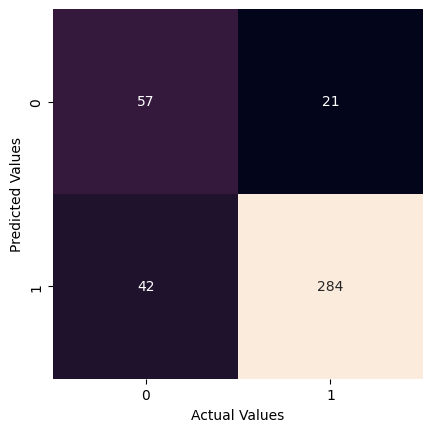

In [ ]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [ ]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.8999921346547114

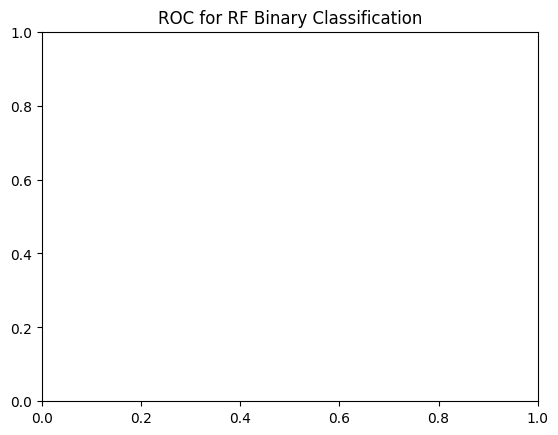

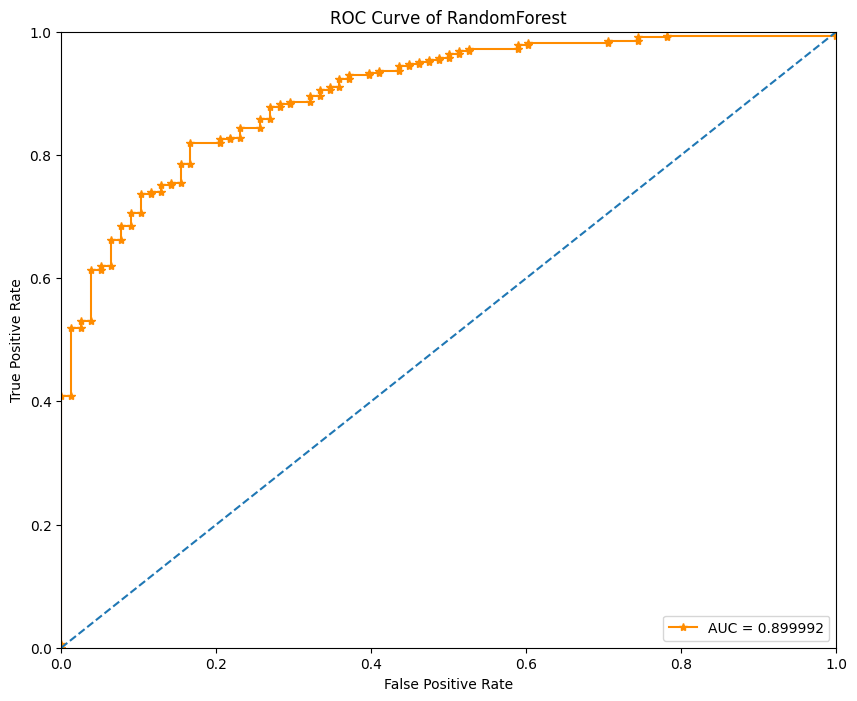

In [ ]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

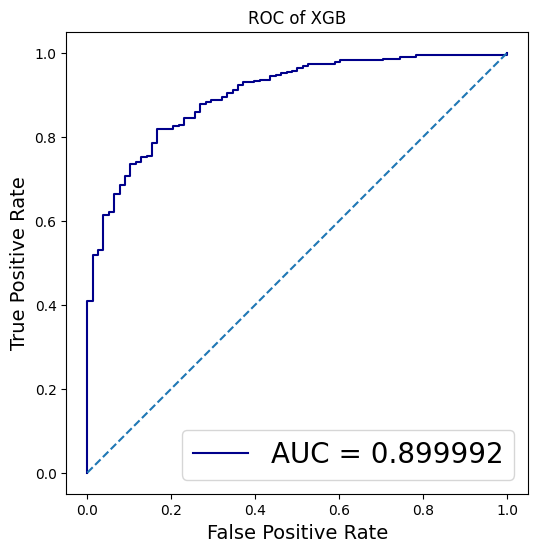

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of XGB')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()


# SHAP

In [ ]:
# SHAP prerequisites check
if 'grid_search' not in locals():
    raise RuntimeError('grid_search is not defined. Run the model training cells before SHAP.')

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# --- 1) Prepare model and SHAP-ready data ---
best_estimator = grid_search.best_estimator_
print(f"Best estimator type: {type(best_estimator).__name__}")

# Recover feature names with priority:
# 1) Saved names before scaling, 2) DataFrame columns, 3) best_genes, 4) fallback labels
if 'gene_names_selected' in locals() and len(gene_names_selected) == np.asarray(X_train).shape[1]:
    feature_names = list(gene_names_selected)
elif isinstance(X_train, pd.DataFrame):
    feature_names = X_train.columns.tolist()
elif 'best_genes' in locals() and len(best_genes) >= np.asarray(X_train).shape[1]:
    feature_names = list(best_genes[:np.asarray(X_train).shape[1]])
else:
    feature_names = [f"Gene_{i}" for i in range(np.asarray(X_train).shape[1])]

X_train_shap = pd.DataFrame(np.asarray(X_train), columns=feature_names)
X_test_shap = pd.DataFrame(np.asarray(X_test), columns=feature_names)

# Use a subset for speed/stability with KernelExplainer
n_background = min(100, len(X_train_shap))
n_explain = min(80, len(X_test_shap))
background = shap.sample(X_train_shap, n_background, random_state=42)
X_explain = shap.sample(X_test_shap, n_explain, random_state=42)

# --- 2) Build SHAP explainer ---
# For SVC with non-linear kernels, KernelExplainer is the most robust choice.
def predict_pos_class(data):
    return best_estimator.predict_proba(data)[:, 1]

explainer = shap.KernelExplainer(predict_pos_class, background)
print("Calculating SHAP values... (this can take a while)")
shap_values = explainer.shap_values(X_explain, nsamples=200)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    # Older SHAP can return [class0, class1]
    shap_matrix = np.asarray(shap_values[1])
else:
    shap_matrix = np.asarray(shap_values)
    if shap_matrix.ndim == 3:
        # (samples, features, classes) -> positive class
        shap_matrix = shap_matrix[:, :, 1]

print("SHAP matrix shape:", shap_matrix.shape)

Best estimator type: XGBClassifier
Calculating SHAP values... (this can take a while)


  0%|          | 0/80 [00:00<?, ?it/s]

SHAP matrix shape: (80, 87)


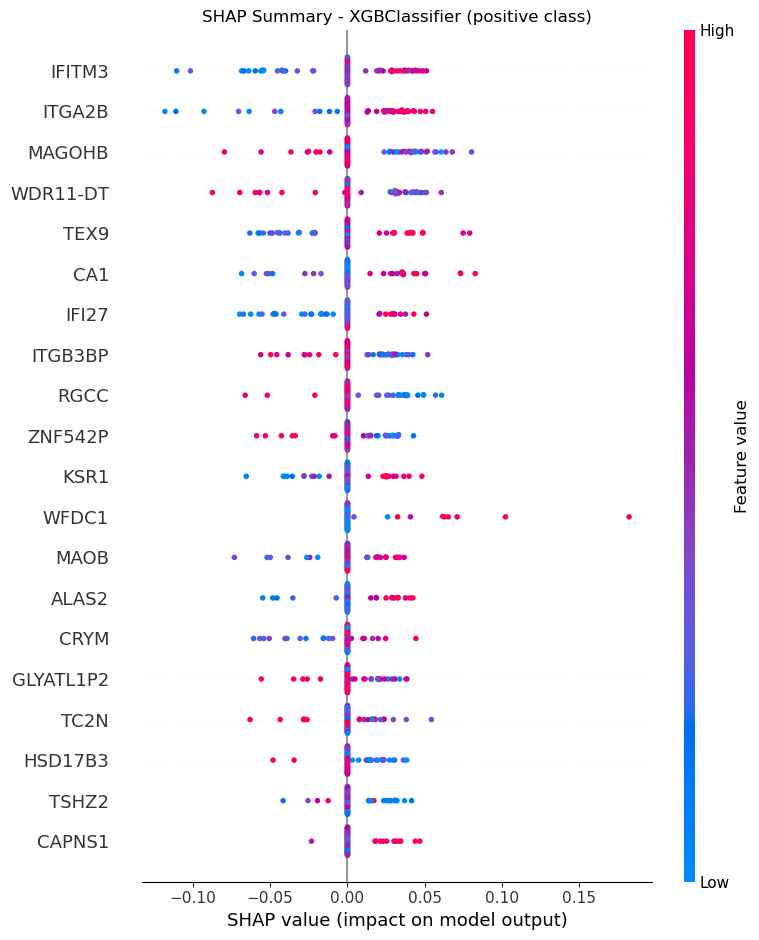

Top 10 Gene Biomarkers:
        Gene  SHAP_Abs_Mean
4     IFITM3       0.022056
3     ITGA2B       0.019036
0     MAGOHB       0.018532
1   WDR11-DT       0.018028
27      TEX9       0.016046
8        CA1       0.013828
17     IFI27       0.013546
6    ITGB3BP       0.012462
14      RGCC       0.010696
2    ZNF542P       0.009256


In [ ]:
# --- 3) Plot SHAP summary ---
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_matrix,
    features=X_explain,
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Summary - {type(best_estimator).__name__} (positive class)")
plt.tight_layout()
plot_name = f"shap_summary_{type(best_estimator).__name__}.png"
# plt.savefig(plot_name, bbox_inches='tight', dpi=300)
plt.show()

# --- 4) Export ranked biomarkers ---
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    'Gene': feature_names,
    'SHAP_Abs_Mean': mean_abs_shap
}).sort_values(by='SHAP_Abs_Mean', ascending=False)

print("Top 10 Gene Biomarkers:")
print(importance_df.head(10))
